In [1]:
import os
os.makedirs("/kaggle/working/images", exist_ok=True)

In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/dgawlik/nyse/prices-split-adjusted.csv
/kaggle/input/datasets/dgawlik/nyse/fundamentals.csv
/kaggle/input/datasets/dgawlik/nyse/prices.csv
/kaggle/input/datasets/dgawlik/nyse/securities.csv


In [3]:
!pip install skorch -q



   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 271.6/271.6 kB 6.8 MB/s eta 0:00:00


In [4]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from skorch import NeuralNetRegressor

torch.manual_seed(42)
np.random.seed(42)
print("GPU disponible :", torch.cuda.is_available())

GPU disponible : False


In [5]:
path = "/kaggle/input/datasets/dgawlik/nyse/prices-split-adjusted.csv"
df = pd.read_csv(path, parse_dates=["date"])
df = df.sort_values("date").reset_index(drop=True)
df.head()

,date,symbol,open,close,low,high,volume
0,2010-01-04,SYMC,18.040001,18.400000,18.01,18.530001,8322300.0
1,2010-01-04,IFF,41.509998,42.009998,41.50,42.020000,286000.0
2,2010-01-04,ILMN,31.120001,30.549999,30.42,31.230000,1793700.0
3,2010-01-04,INTC,20.790001,20.879999,20.73,21.030001,47800900.0
4,2010-01-04,INTU,31.090000,30.809999,30.77,31.150000,2353000.0


In [6]:
print(df.shape)
df.info()
print(df.isnull().sum())
print("Nombre d'entreprises :", df["symbol"].nunique())
print("Période :", df["date"].min(), "->", df["date"].max())
df.describe()

(851264, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 851264 entries, 0 to 851263
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype         
---  ------  --------------   -----         
 0   date    851264 non-null  datetime64[ns]
 1   symbol  851264 non-null  object        
 2   open    851264 non-null  float64       
 3   close   851264 non-null  float64       
 4   low     851264 non-null  float64       
 5   high    851264 non-null  float64       
 6   volume  851264 non-null  float64       
dtypes: datetime64[ns](1), float64(5), object(1)
memory usage: 45.5+ MB
date      0
symbol    0
open      0
close     0
low       0
high      0
volume    0
dtype: int64
Nombre d'entreprises : 501
Période : 2010-01-04 00:00:00 -> 2016-12-30 00:00:00


,date,open,close,low,high,volume
count,851264,851264.000000,851264.000000,851264.000000,851264.000000,8.512640e+05
mean,2013-07-21 02:56:29.294038016,64.993618,65.011913,64.336541,65.639748,5.415113e+06
min,2010-01-04 00:00:00,1.660000,1.590000,1.500000,1.810000,0.000000e+00
25%,2011-10-19 00:00:00,31.270000,31.292776,30.940001,31.620001,1.221500e+06
50%,2013-08-02 00:00:00,48.459999,48.480000,47.970001,48.959999,2.476250e+06
75%,2015-04-24 00:00:00,75.120003,75.139999,74.400002,75.849998,5.222500e+06
max,2016-12-30 00:00:00,1584.439941,1578.130005,1549.939941,1600.930054,8.596434e+08
std,NaN,75.203893,75.201216,74.459518,75.906861,1.249468e+07


In [7]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/dgawlik/nyse/prices-split-adjusted.csv
/kaggle/input/datasets/dgawlik/nyse/fundamentals.csv
/kaggle/input/datasets/dgawlik/nyse/prices.csv
/kaggle/input/datasets/dgawlik/nyse/securities.csv


In [8]:
df.describe()

,date,open,close,low,high,volume
count,851264,851264.000000,851264.000000,851264.000000,851264.000000,8.512640e+05
mean,2013-07-21 02:56:29.294038016,64.993618,65.011913,64.336541,65.639748,5.415113e+06
min,2010-01-04 00:00:00,1.660000,1.590000,1.500000,1.810000,0.000000e+00
25%,2011-10-19 00:00:00,31.270000,31.292776,30.940001,31.620001,1.221500e+06
50%,2013-08-02 00:00:00,48.459999,48.480000,47.970001,48.959999,2.476250e+06
75%,2015-04-24 00:00:00,75.120003,75.139999,74.400002,75.849998,5.222500e+06
max,2016-12-30 00:00:00,1584.439941,1578.130005,1549.939941,1600.930054,8.596434e+08
std,NaN,75.203893,75.201216,74.459518,75.906861,1.249468e+07


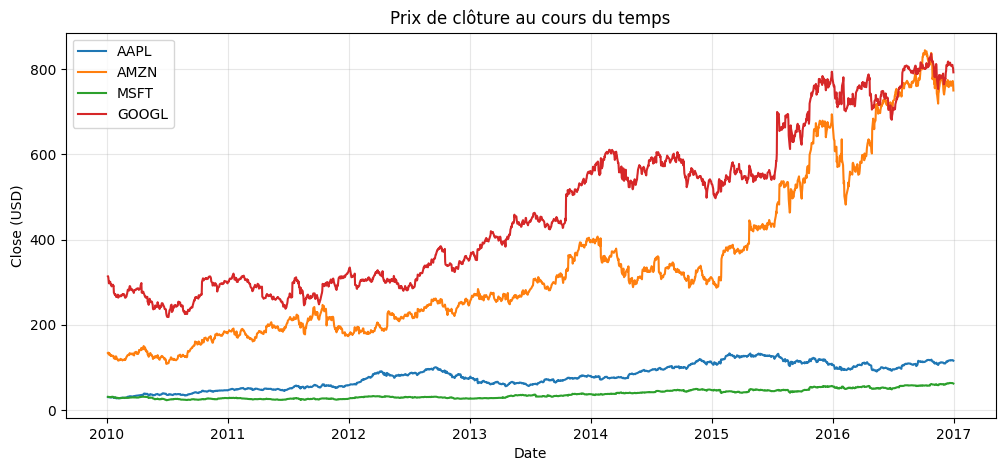

In [9]:
tickers = ["AAPL", "AMZN", "MSFT", "GOOGL"]
plt.figure(figsize=(12, 5))
for t in tickers:
    sub = df[df.symbol == t]
    if len(sub) > 0:
        plt.plot(sub["date"], sub["close"], label=t)
plt.title("Prix de clôture au cours du temps")
plt.xlabel("Date"); plt.ylabel("Close (USD)")
plt.legend(); plt.grid(alpha=0.3); plt.savefig("/kaggle/working/images/p1_prix_temps.png", dpi=120, bbox_inches="tight")
plt.show()

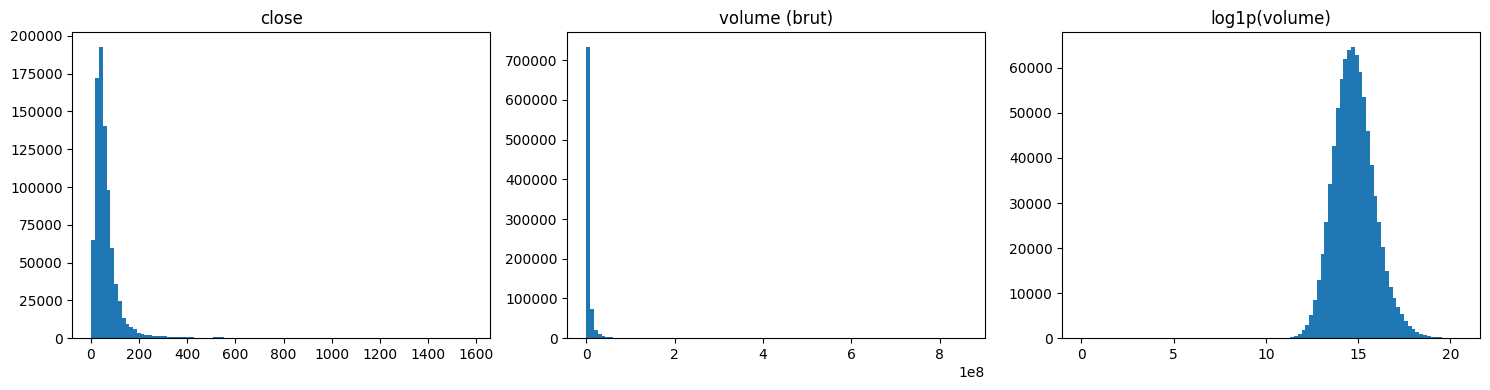

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(df["close"], bins=100); ax[0].set_title("close")
ax[1].hist(df["volume"], bins=100); ax[1].set_title("volume (brut)")
ax[2].hist(np.log1p(df["volume"]), bins=100); ax[2].set_title("log1p(volume)")
plt.tight_layout()
plt.savefig("/kaggle/working/images/p1_distributions.png", dpi=120, bbox_inches="tight")
plt.show()

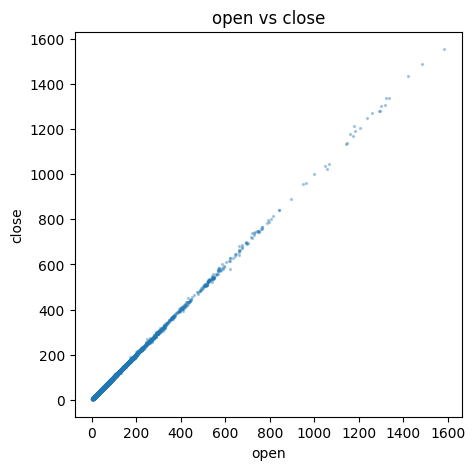

In [11]:
s = df.sample(20000, random_state=42)
plt.figure(figsize=(5, 5))
plt.scatter(s["open"], s["close"], s=2, alpha=0.3)
plt.xlabel("open"); plt.ylabel("close"); plt.title("open vs close")
plt.savefig("/kaggle/working/images/p1_scatter.png", dpi=120, bbox_inches="tight")
plt.show()

In [12]:
# Features et cible
df["log_volume"] = np.log1p(df["volume"])
features = ["open", "low", "high", "log_volume"]

# Découpage par date
train = df[df.date < "2016-01-01"]
test  = df[df.date >= "2016-01-01"]
print(len(train), len(test))

X_train, y_train = train[features].values, train[["close"]].values
X_test,  y_test  = test[features].values,  test[["close"]].values

# Standardisation (fit sur train uniquement)
sx, sy = StandardScaler(), StandardScaler()
X_train = sx.fit_transform(X_train).astype("float32")
X_test  = sx.transform(X_test).astype("float32")
y_train_s = sy.fit_transform(y_train).astype("float32")
y_test_s  = sy.transform(y_test).astype("float32")

725139 126125


In [13]:
class MLP(nn.Module):
    def __init__(self, in_features=4, hidden=64, dropout=0.0, batchnorm=False):
        super().__init__()
        layers = [nn.Linear(in_features, hidden)]
        if batchnorm: layers.append(nn.BatchNorm1d(hidden))
        layers += [nn.ReLU(), nn.Dropout(dropout),
                   nn.Linear(hidden, hidden // 2)]
        if batchnorm: layers.append(nn.BatchNorm1d(hidden // 2))
        layers += [nn.ReLU(), nn.Dropout(dropout),
                   nn.Linear(hidden // 2, 1)]
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x)

In [14]:
from torch.utils.data import TensorDataset, DataLoader

def train_model(model, lr, optimizer_cls, epochs, weight_decay=0.0,
                patience=None, batch_size=256):
    Xtr, ytr = torch.tensor(X_train), torch.tensor(y_train_s)
    Xte, yte = torch.tensor(X_test),  torch.tensor(y_test_s)
    loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=batch_size, shuffle=True)
    opt = optimizer_cls(model.parameters(), lr=lr, weight_decay=weight_decay)
    crit = nn.MSELoss()
    hist = {"train_loss": [], "test_loss": [], "train_r2": [], "test_r2": []}
    best, wait = float("inf"), 0

    for ep in range(epochs):
        model.train()
        for xb, yb in loader:
            opt.zero_grad()
            loss = crit(model(xb), yb)
            loss.backward(); opt.step()

        model.eval()
        with torch.no_grad():
            ptr, pte = model(Xtr), model(Xte)
            hist["train_loss"].append(crit(ptr, ytr).item())
            hist["test_loss"].append(crit(pte, yte).item())
            hist["train_r2"].append(r2_score(ytr.numpy(), ptr.numpy()))
            hist["test_r2"].append(r2_score(yte.numpy(), pte.numpy()))

        if patience:
            if hist["test_loss"][-1] < best - 1e-6:
                best, wait = hist["test_loss"][-1], 0
            else:
                wait += 1
                if wait >= patience: break
    return hist

def plot_curves(hist, title="", save_as=None):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(hist["train_loss"], label="train"); ax[0].plot(hist["test_loss"], label="test")
    ax[0].set_title(f"Loss / Epochs {title}"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(hist["train_r2"], label="train"); ax[1].plot(hist["test_r2"], label="test")
    ax[1].set_title(f"R² / Epochs {title}"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout()
    if save_as:
        plt.savefig(f"/kaggle/working/images/{save_as}", dpi=120, bbox_inches="tight")
    plt.show()

In [15]:
from torch.utils.data import TensorDataset, DataLoader

def train_model(model, lr, optimizer_cls, epochs, weight_decay=0.0,
                patience=None, batch_size=256):
    Xtr, ytr = torch.tensor(X_train), torch.tensor(y_train_s)
    Xte, yte = torch.tensor(X_test),  torch.tensor(y_test_s)
    loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=batch_size, shuffle=True)
    opt = optimizer_cls(model.parameters(), lr=lr, weight_decay=weight_decay)
    crit = nn.MSELoss()
    hist = {"train_loss": [], "test_loss": [], "train_r2": [], "test_r2": []}
    best, wait = float("inf"), 0

    for ep in range(epochs):
        model.train()
        for xb, yb in loader:
            opt.zero_grad()
            loss = crit(model(xb), yb)
            loss.backward(); opt.step()

        model.eval()
        with torch.no_grad():
            ptr, pte = model(Xtr), model(Xte)
            hist["train_loss"].append(crit(ptr, ytr).item())
            hist["test_loss"].append(crit(pte, yte).item())
            hist["train_r2"].append(r2_score(ytr.numpy(), ptr.numpy()))
            hist["test_r2"].append(r2_score(yte.numpy(), pte.numpy()))

        if patience:
            if hist["test_loss"][-1] < best - 1e-6:
                best, wait = hist["test_loss"][-1], 0
            else:
                wait += 1
                if wait >= patience:
                    break
    return hist

def plot_curves(hist, title="", save_as=None):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(hist["train_loss"], label="train"); ax[0].plot(hist["test_loss"], label="test")
    ax[0].set_title(f"Loss / Epochs {title}"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(hist["train_r2"], label="train"); ax[1].plot(hist["test_r2"], label="test")
    ax[1].set_title(f"R² / Epochs {title}"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout()
    if save_as:
        plt.savefig(f"/kaggle/working/images/{save_as}", dpi=120, bbox_inches="tight")
    plt.show()

In [16]:
df["log_volume"] = np.log1p(df["volume"])
features = ["open", "low", "high", "log_volume"]

train = df[df.date < "2016-01-01"]
test  = df[df.date >= "2016-01-01"]
print(len(train), len(test))

X_train, y_train = train[features].values, train[["close"]].values
X_test,  y_test  = test[features].values,  test[["close"]].values

sx, sy = StandardScaler(), StandardScaler()
X_train = sx.fit_transform(X_train).astype("float32")
X_test  = sx.transform(X_test).astype("float32")
y_train_s = sy.fit_transform(y_train).astype("float32")
y_test_s  = sy.transform(y_test).astype("float32")
print(X_train.shape, y_train_s.shape, X_test.shape)

725139 126125
(725139, 4) (725139, 1) (126125, 4)


In [17]:
idx = np.random.choice(len(X_train), 50000, replace=False)
Xs, ys = X_train[idx], y_train_s[idx]

net = NeuralNetRegressor(
    MLP, criterion=nn.MSELoss, optimizer=torch.optim.Adam,
    max_epochs=20, batch_size=256, verbose=0, train_split=None)

params = {
    "lr": [1e-2, 1e-3],
    "optimizer": [torch.optim.Adam, torch.optim.SGD],
    "max_epochs": [20, 40],
    "module__hidden": [32, 64],
}
gs = GridSearchCV(net, params, cv=3, scoring="neg_mean_squared_error", n_jobs=1)
gs.fit(Xs, ys)
print("Meilleurs paramètres :", gs.best_params_)
print("Meilleur score :", gs.best_score_)

Meilleurs paramètres : {'lr': 0.001, 'max_epochs': 20, 'module__hidden': 32, 'optimizer': <class 'torch.optim.adam.Adam'>}
Meilleur score : -0.00021172705358670404


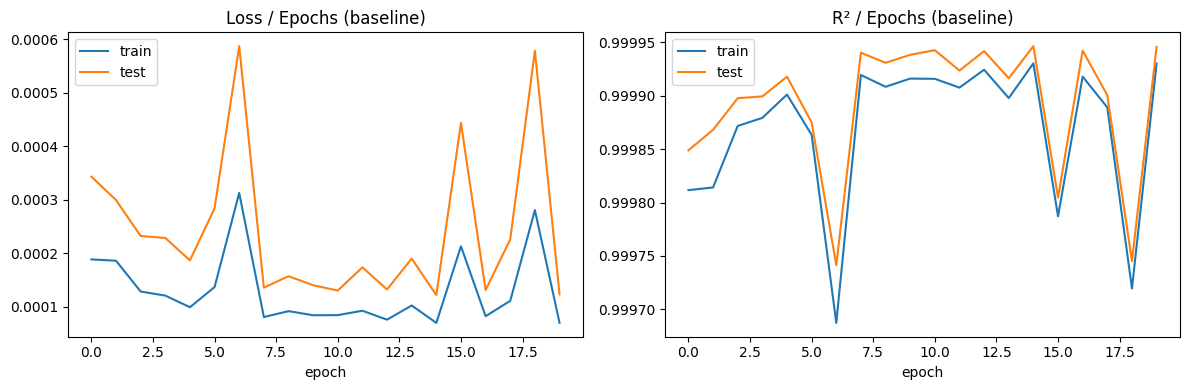

In [18]:
bp = gs.best_params_
torch.manual_seed(42)
base = MLP(hidden=bp["module__hidden"])
h_base = train_model(base, bp["lr"], bp["optimizer"], bp["max_epochs"])
plot_curves(h_base, "(baseline)")

In [19]:
from torch.utils.data import TensorDataset, DataLoader

def train_model(model, lr, optimizer_cls, epochs, weight_decay=0.0,
                patience=None, batch_size=256):
    Xtr, ytr = torch.tensor(X_train), torch.tensor(y_train_s)
    Xte, yte = torch.tensor(X_test),  torch.tensor(y_test_s)
    loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=batch_size, shuffle=True)
    opt = optimizer_cls(model.parameters(), lr=lr, weight_decay=weight_decay)
    crit = nn.MSELoss()
    hist = {"train_loss": [], "test_loss": [], "train_r2": [], "test_r2": []}
    best, wait = float("inf"), 0

    for ep in range(epochs):
        model.train()
        for xb, yb in loader:
            opt.zero_grad()
            loss = crit(model(xb), yb)
            loss.backward(); opt.step()

        model.eval()
        with torch.no_grad():
            ptr, pte = model(Xtr), model(Xte)
            hist["train_loss"].append(crit(ptr, ytr).item())
            hist["test_loss"].append(crit(pte, yte).item())
            hist["train_r2"].append(r2_score(ytr.numpy(), ptr.numpy()))
            hist["test_r2"].append(r2_score(yte.numpy(), pte.numpy()))

        if patience:
            if hist["test_loss"][-1] < best - 1e-6:
                best, wait = hist["test_loss"][-1], 0
            else:
                wait += 1
                if wait >= patience: break
    return hist

def plot_curves(hist, title="", save_as=None):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(hist["train_loss"], label="train"); ax[0].plot(hist["test_loss"], label="test")
    ax[0].set_title(f"Loss / Epochs {title}"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(hist["train_r2"], label="train"); ax[1].plot(hist["test_r2"], label="test")
    ax[1].set_title(f"R² / Epochs {title}"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout()
    if save_as:
        plt.savefig(f"/kaggle/working/images/{save_as}", dpi=120, bbox_inches="tight")
    plt.show()

In [20]:
def evaluate(model, X, y_s):
    model.eval()
    with torch.no_grad():
        p = model(torch.tensor(X)).numpy()
    p_usd, y_usd = sy.inverse_transform(p), sy.inverse_transform(y_s)
    return {"MSE": mean_squared_error(y_usd, p_usd),
            "RMSE": mean_squared_error(y_usd, p_usd) ** 0.5,
            "MAE": mean_absolute_error(y_usd, p_usd),
            "R2": r2_score(y_usd, p_usd)}

print("Train :", evaluate(base, X_train, y_train_s))
print("Test  :", evaluate(base, X_test, y_test_s))

Train : {'MSE': 0.32850053906440735, 'RMSE': 0.5731496655014354, 'MAE': 0.2990238666534424, 'R2': 0.9999301433563232}
Test  : {'MSE': 0.5786880850791931, 'RMSE': 0.7607155086359112, 'MAE': 0.39234405755996704, 'R2': 0.9999457597732544}


In [21]:
configs = {
    "Baseline":        dict(model=dict(), wd=0.0, pat=None),
    "Dropout 0.2":     dict(model=dict(dropout=0.2), wd=0.0, pat=None),
    "L2 (wd=1e-4)":    dict(model=dict(), wd=1e-4, pat=None),
    "BatchNorm":       dict(model=dict(batchnorm=True), wd=0.0, pat=None),
    "Early stopping":  dict(model=dict(), wd=0.0, pat=5),
    "Combiné":         dict(model=dict(dropout=0.2), wd=1e-4, pat=5),
}

results, hists = [], {}
for name, c in configs.items():
    torch.manual_seed(42)
    m = MLP(hidden=bp["module__hidden"], **c["model"])
    h = train_model(m, bp["lr"], bp["optimizer"], bp["max_epochs"],
                    weight_decay=c["wd"], patience=c["pat"])
    hists[name] = h
    tr, te = evaluate(m, X_train, y_train_s), evaluate(m, X_test, y_test_s)
    results.append({"Modèle": name, "Epochs": len(h["train_loss"]),
                    "Train RMSE": tr["RMSE"], "Test RMSE": te["RMSE"],
                    "Test MAE": te["MAE"], "Test R2": te["R2"],
                    "Écart (test-train RMSE)": te["RMSE"] - tr["RMSE"]})

comparison = pd.DataFrame(results).round(4)
comparison

,Modèle,Epochs,Train RMSE,Test RMSE,Test MAE,Test R2,Écart (test-train RMSE)
0,Baseline,20,0.5731,0.7607,0.3923,0.9999,0.1876
1,Dropout 0.2,20,3.8910,6.2907,2.2444,0.9963,2.3997
2,L2 (wd=1e-4),20,0.6872,0.9093,0.4685,0.9999,0.2221
3,BatchNorm,20,3.3942,5.1039,2.5296,0.9976,1.7097
4,Early stopping,20,0.5731,0.7607,0.3923,0.9999,0.1876
5,Combiné,6,4.6309,7.6423,2.3953,0.9945,3.0114


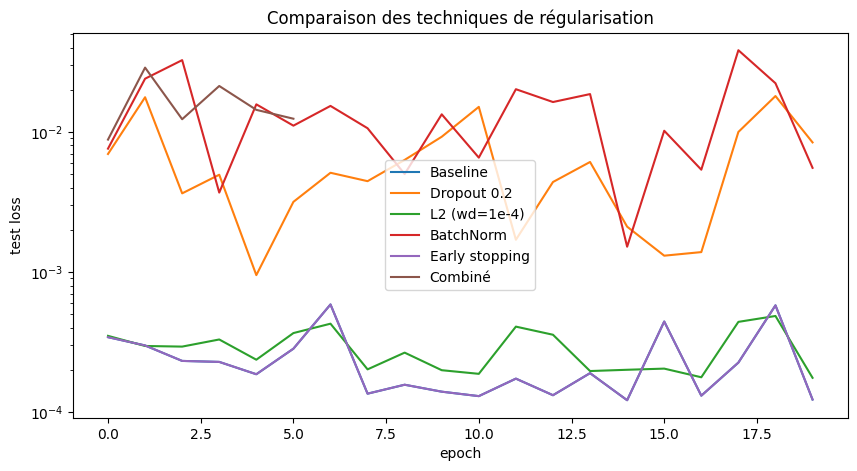

In [22]:
plt.figure(figsize=(10, 5))
for name, h in hists.items():
    plt.plot(h["test_loss"], label=name)
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("test loss")
plt.title("Comparaison des techniques de régularisation")
plt.legend()
plt.savefig("/kaggle/working/images/p1_comparaison_reg.png", dpi=120, bbox_inches="tight")
plt.show()

In [23]:
import os
os.makedirs("/kaggle/working/images", exist_ok=True)

In [24]:
import os
print(os.listdir("/kaggle/working/images"))

['p1_distributions.png', 'p1_scatter.png', 'p1_comparaison_reg.png', 'p1_prix_temps.png']


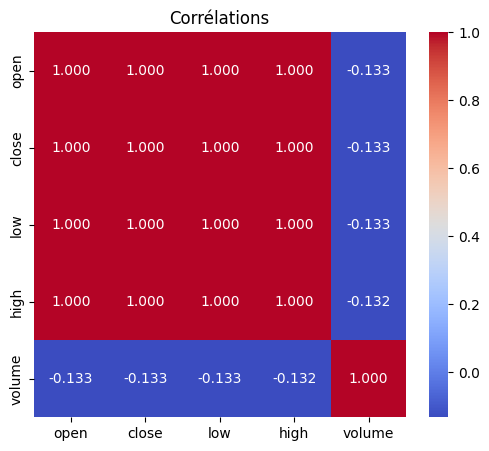

In [25]:
cols = ["open", "close", "low", "high", "volume"]
plt.figure(figsize=(6, 5))
sns.heatmap(df[cols].corr(), annot=True, cmap="coolwarm", fmt=".3f")
plt.title("Corrélations")
plt.savefig("/kaggle/working/images/p1_correlation.png", dpi=120, bbox_inches="tight")
plt.show()

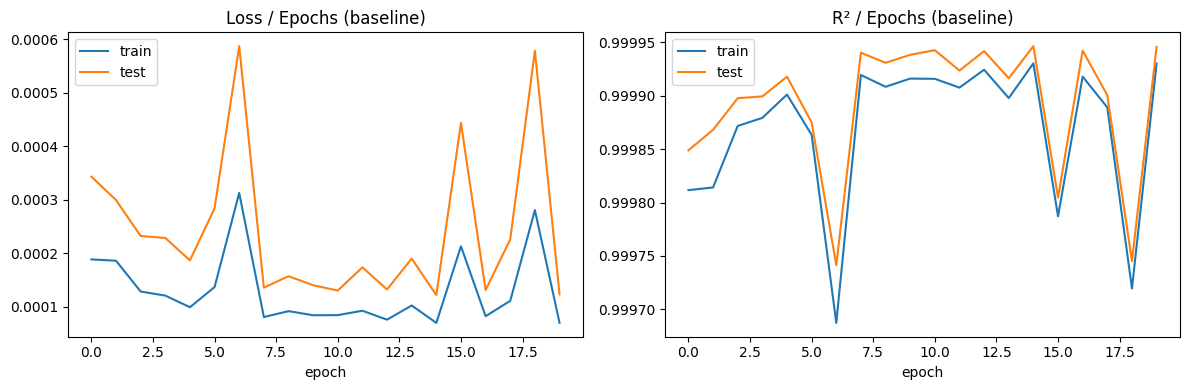

In [26]:
plot_curves(h_base, "(baseline)", save_as="p1_courbes_baseline.png")

In [27]:
print(sorted(os.listdir("/kaggle/working/images")))

['p1_comparaison_reg.png', 'p1_correlation.png', 'p1_courbes_baseline.png', 'p1_distributions.png', 'p1_prix_temps.png', 'p1_scatter.png']
